In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Flatten, Rescaling
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [6]:
data = pd.read_csv("creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [14]:
X = data.drop("Class", axis = 1).values
y = data["Class"]

In [15]:
scaler = StandardScaler()

In [18]:
X_scaled = scaler.fit_transform(X)

In [19]:
X_normal = X_scaled[y==0]

In [20]:
trainX, testX = train_test_split(X_normal, test_size = 0.2, random_state = 42)

In [22]:
print("TrainX shape: ", trainX.shape)
print("TestX shape: ", testX.shape)

TrainX shape:  (227452, 30)
TestX shape:  (56863, 30)


In [28]:
model = Sequential([
    Input(shape=(30, )),
    Dense(16, activation = "relu"),
    Dense(8, activation = "relu"),
    Dense(16, activation = "relu"),
    Dense(30, activation = "softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer = Adam(learning_rate = 0.001),
    loss = "mse",
    metrics = ["accuracy"]
)

In [30]:
history = model.fit(
    trainX,
    trainX,
    validation_data = (testX, testX),
    batch_size = 256, 
    epochs = 10,
    verbose = 1
)

Epoch 1/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3161 - loss: 0.9090 - val_accuracy: 0.4218 - val_loss: 0.8950
Epoch 2/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4467 - loss: 0.8883 - val_accuracy: 0.4780 - val_loss: 0.8892
Epoch 3/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4898 - loss: 0.8842 - val_accuracy: 0.5037 - val_loss: 0.8871
Epoch 4/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5083 - loss: 0.8826 - val_accuracy: 0.5184 - val_loss: 0.8859
Epoch 5/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5192 - loss: 0.8817 - val_accuracy: 0.5203 - val_loss: 0.8853
Epoch 6/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5241 - loss: 0.8812 - val_accuracy: 0.5287 - val_loss: 0.8848
Epoch 7/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5283 - loss: 0.8809 - val_accuracy: 0.5332 - val_loss: 0.8846
Epoch 8/10
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5307 - loss: 0.8807 - val_accuracy: 0.

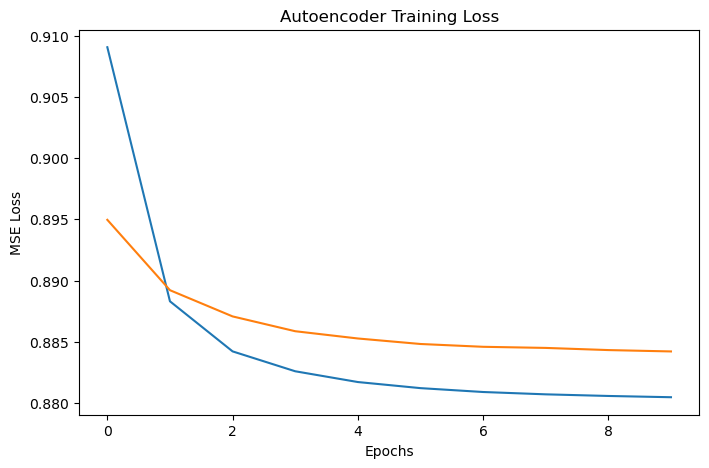

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.show()

In [35]:
x_reconstruct = model.predict(X_scaled, verbose = 0)
reconstruction_error = np.mean(np.square(X_scaled-x_reconstruct), axis = 1)

In [36]:
print("Reconstruction Error: ", reconstruction_error[:10])

Reconstruction Error:  [0.38140627 0.28985393 1.38720006 0.77982307 0.48475832 0.27932239
 0.37493453 1.8832181  0.60320479 0.38143283]


In [37]:
x_test_reconstruct = model.predict(testX, verbose = 0)
x_test_reconstruction_error = np.mean(np.square(testX-x_test_reconstruct), axis = 1)
print("TestX reconstruction error: ", x_test_reconstruction_error[:10])

TestX reconstruction error:  [0.23856783 0.26221803 0.72093072 0.33407103 1.08094414 0.45511177
 1.22106247 0.57325829 0.36408549 0.86589064]


In [40]:
threshold = np.percentile(x_test_reconstruction_error, 95)
print("Threshold: ", threshold)

Threshold:  1.7933655325575684


In [41]:
y_pred = (reconstruction_error>threshold).astype(int)

In [42]:
print("Predicted Classes: ", y_pred[:20])

Predicted Classes:  [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0]


In [44]:
print("Confusion Metrics: ", confusion_matrix(y, y_pred))
print("Classification Report: ", classification_report(y, y_pred))

Confusion Metrics:  [[270304  14011]
 [    61    431]]
Classification Report:                precision    recall  f1-score   support

           0       1.00      0.95      0.97    284315
           1       0.03      0.88      0.06       492

    accuracy                           0.95    284807
   macro avg       0.51      0.91      0.52    284807
weighted avg       1.00      0.95      0.97    284807



In [46]:
print("Number of anomalies detected: ", y_pred.sum())

Number of anomalies detected:  14442


In [47]:
X.shape

(284807, 30)